# SGD batch size

Reads `results/ablations/batch_size_mmds.csv` and `batch_size_nmds.csv` (made by `ablations.py embed / evaluate /
collect`): metric SGD on genomes, Tasic and MNIST, non-metric SGD on genomes, one seed each. One column per dataset and
kind of MDS; each point is one batch size (labelled), at its runtime. Top: stress-1 of the final embedding (metric
stress-1 for metric MDS, Kruskal's for non-metric). Bottom: triplet accuracy. Every panel has its own y-axis, all with
the same span (0.015), so that tiny differences are not blown up; the label of batch size 300 is hidden where it
overlaps another label; all panels share the x-axis (whole decades). With several seeds,
points are means.

In [1]:
import sys
sys.path.insert(0, "..")  # make the modules in code/ importable

import matplotlib.pyplot as plt
import pandas as pd

import paths

paths.FIGURES.mkdir(exist_ok=True)
if paths.STYLE.exists():
    plt.style.use(paths.STYLE)
else:
    print(f"{paths.STYLE} not found: using matplotlib's default style. Copy your mpl_style.txt there.")

df = pd.concat([pd.read_csv(paths.RESULTS / "ablations" / f"batch_size_{kind}.csv") for kind in ("mmds", "nmds")])

In [2]:
import numpy as np
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

PANELS = [  # (dataset, method, title), in this order
    ("genomes", "sgd_mmds", "Genomes, metric"),
    ("genomes", "sgd_nmds", "Genomes, non-metric"),
    ("tasic", "sgd_mmds", "Tasic, metric"),
    ("mnist", "sgd_mmds", "MNIST, metric"),
]
ROWS = [("stress1", "Stress-1"), ("triplet_acc", "Triplet accuracy")]
Y_SPAN = 0.015  # the same y-range in every panel
HIDE_IF_OVERLAPPING = 300  # batch size whose label is hidden where it overlaps another label


def y_limits(values):
    """Y_SPAN around the middle of the values (wider, with a warning, if they do not fit)."""
    lo, hi = np.min(values), np.max(values)
    span = Y_SPAN
    if hi - lo > 0.9 * Y_SPAN:
        span = 1.1 * (hi - lo)
        print(f"y-range widened to {span:.3f}: the values do not fit in Y_SPAN = {Y_SPAN}")
    mid = (lo + hi) / 2
    return mid - span / 2, mid + span / 2


def hide_overlapping_labels(fig, labels):
    """Hide the HIDE_IF_OVERLAPPING label of a panel where it overlaps another label of that panel."""
    fig.canvas.draw()  # the labels' positions are known only after drawing (with the final layout)
    renderer = fig.canvas.get_renderer()
    for panel in labels:
        boxes = {b: text.get_window_extent(renderer) for b, text in panel.items()}
        if HIDE_IF_OVERLAPPING in boxes and any(
            boxes[HIDE_IF_OVERLAPPING].overlaps(box) for b, box in boxes.items() if b != HIDE_IF_OVERLAPPING
        ):
            panel[HIDE_IF_OVERLAPPING].set_visible(False)


def batch_size_figure():
    df["stress1"] = df.stress1_metric.where(df.method == "sgd_mmds", df.stress1_nonmetric)
    g = df.groupby(["dataset", "method", "batch_size"])[["runtime", "stress1", "triplet_acc"]].mean().reset_index()
    panels = [p for p in PANELS if ((g.dataset == p[0]) & (g.method == p[1])).any()]

    # shared x-axis: whole decades around all runtimes
    xlim = 10.0 ** np.floor(np.log10(g.runtime.min())), 10.0 ** np.ceil(np.log10(g.runtime.max()))

    labels = []  # per panel: {batch size: its label}
    fig, axs = plt.subplots(2, len(panels), figsize=(5.5, 3.4), layout="constrained", squeeze=False)
    for j, (dataset, method, title) in enumerate(panels):
        sub = g[(g.dataset == dataset) & (g.method == method)].sort_values("batch_size")
        for i, (column, ylabel) in enumerate(ROWS):
            ax = axs[i, j]
            ax.plot(sub.runtime, sub[column], ".-", color=f"C{j}")
            labels.append({
                b: ax.annotate(f"{b}", (x, v), textcoords="offset points", xytext=(2, 2), fontsize=6, color=f"C{j}")
                for x, v, b in zip(sub.runtime, sub[column], sub.batch_size)
            })
            ax.set_xscale("log")
            ax.set_xlim(*xlim)
            ax.xaxis.set_major_locator(LogLocator(base=10))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
            ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
            ax.xaxis.set_minor_formatter(NullFormatter())
            ax.set_ylim(*y_limits(sub[column]))
            if i == 0:
                ax.set_title(title)
            if i == len(ROWS) - 1:
                ax.set_xlabel("Runtime (s)")
            if j == 0:
                ax.set_ylabel(ylabel)

    hide_overlapping_labels(fig, labels)
    for ext in ("pdf", "png"):
        fig.savefig(paths.FIGURES / f"sgd-batch-size.{ext}", dpi=300)
    return fig

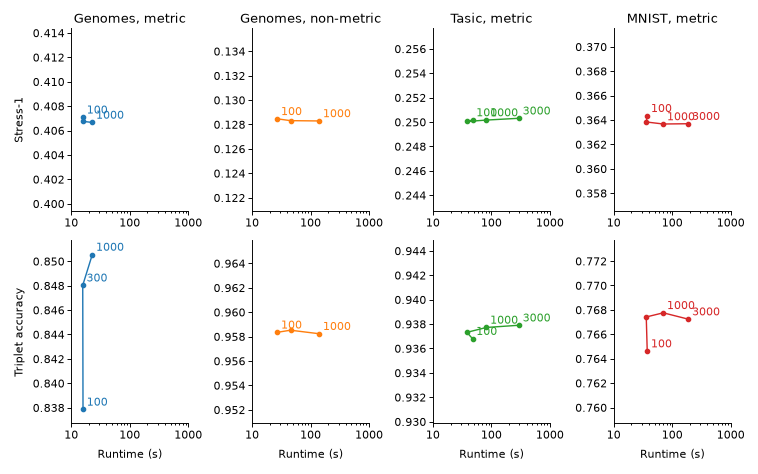

In [3]:
batch_size_figure();